In [1]:
# Start with loading all necessary libraries
import numpy as np
import pandas as pd
from os import path
from PIL import Image
from wordcloud import WordCloud, STOPWORDS, ImageColorGenerator
import json

import matplotlib.pyplot as plt

import sys, os, sqlite3

sys.path.insert(0, os.path.join(os.getcwd(), '..'))
from framework import init_env
init_env()
path = os.path.join("..", os.environ["DB_FILE"])
database = sqlite3.connect(path)

# load the existing data
# Opening JSON file
path = os.path.join("..", os.environ["CACHED_TRANSLATIONS"])
with open(path, "r") as f:
    translations = json.load(f)

import re


In [2]:
edition = 2024

sql = """
SELECT O.position, A.name, S.rowid AS song_id, S.en_title, S.year
FROM OCCURANCE O 
INNER JOIN Song S ON S.rowid = O.song
INNER JOIN Artist A ON A.rowid = S.artist
WHERE O.edition = {current}
ORDER BY O.position ASC
""".format(current=edition)

df = pd.read_sql_query(sql, database).set_index("position")
df.head()

,name,song_id,en_title,year
position,,,,
1,Queen,3135,bohemian rhapsody,1975
2,Coldplay,835,fix you,2005
3,Eagles,1211,hotel california,1977
4,Danny Vera,4708,roller coaster,2019
5,Billy Joel,420,piano man,1973


In [4]:
# text_arr = []
# df = df.reset_index()  # make sure indexes pair with number of rows

# for index, row in df.iterrows():
#     print(row['position'])
#     text_arr.extend([row['en_title']] * 2001 - int(row['position']))
# text = " ".join(text_arr)
text = " ".join(title for title in df.en_title)

print ("There are {} words in the combination of all titles.".format(len(text)))


There are 32131 words in the combination of all titles.


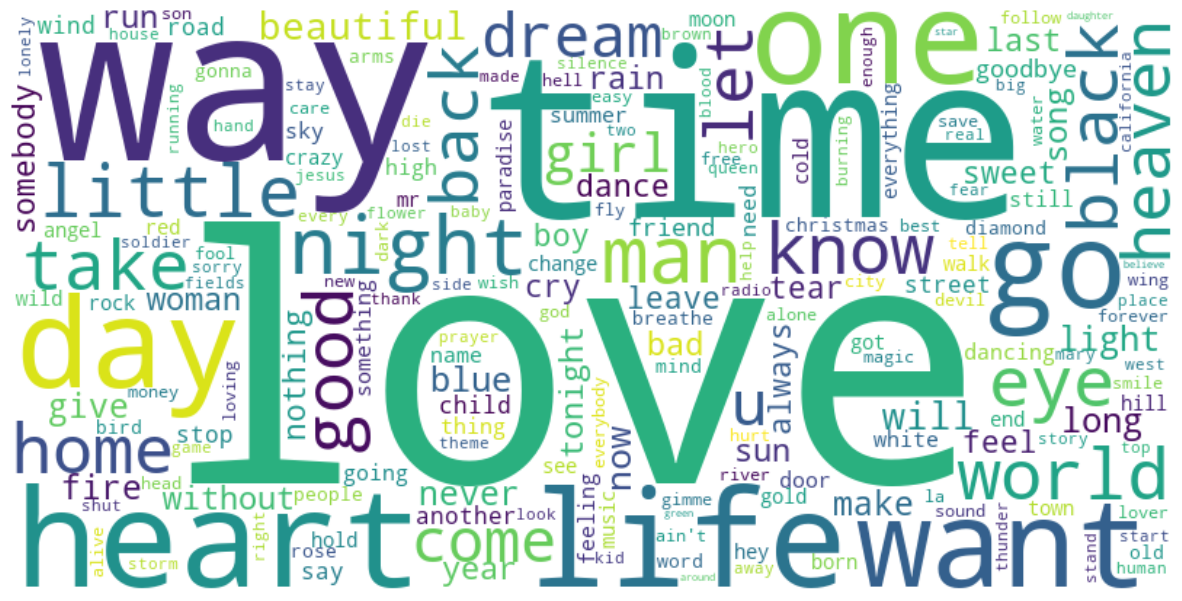

In [5]:
# Create stopword list:
stopwords = set(STOPWORDS)
stopwords.update(["albumversie", "live", "unplugged", "Album", "version", "de", "het"])

# Generate a word cloud image
wordcloud = WordCloud(stopwords=stopwords, background_color="white", width=800, height=400).generate(text)

# Display the generated image:
# the matplotlib way:
plt.figure(figsize=(15,10))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
plt.show()
